# Prediciendo la diabetes


In [2]:
# Librerias

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pickle
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
from pickle import dump

## Paso 1: Carga del conjunto de datos

In [3]:
df = pd.read_csv('https://breathecode.herokuapp.com/asset/internal-link?id=930&path=diabetes.csv')

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## Paso 2: Realiza un EDA completo

### 1er Paso EDA: Planteamiento del problema y recopilación de datos

Buscamos una manera de predecir si un paciente tiene o no diabetes, en base a medidas diagnósticas.

Nuestra variable objetivo será: ***'Outcome'*** 

### 2do Paso EDA: Exploración y limpieza de datos


In [4]:
df.shape

(768, 9)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


- Nuestro dataframe tiene 768 observaciones y 9 variables. Para el modelo de clásificación, vamos a tomar como variable dependiente **'Outcome'** y como predictoras todas las restantes. 

- Nuestras variables numéricas son 9: **'Pregnancies'**, **'Glucose'**, **'BloodPressure'**, **'SkinThickness'**, **'Insulin'**, **'BMI'** y **'DiabetesPedigreeFunction'**, **'Age'** y nuestra objetivo **'Outcome'**

- No tenemos variables categóricas.

- Por otro lado podemos ver que no hay valores nulos y que el número de filas es de 768, que corresponden al número de registros de pacientes.

Ahora procedemos a analizar si hay duplicados y en su caso, a eliminarlos:

In [6]:
df.duplicated().sum()

np.int64(0)

No tenemos duplicados.

Ahora nos correspondería eliminar la información irrelevante, pero considero que no hay variables irrelevantes para descartar, es más, creo que todas son medidas que pueden influir en nuestra predicción.

### 3er Paso EDA: Análisis de variables univariante

**Análisis sobre variables numéricas**

In [7]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='str')

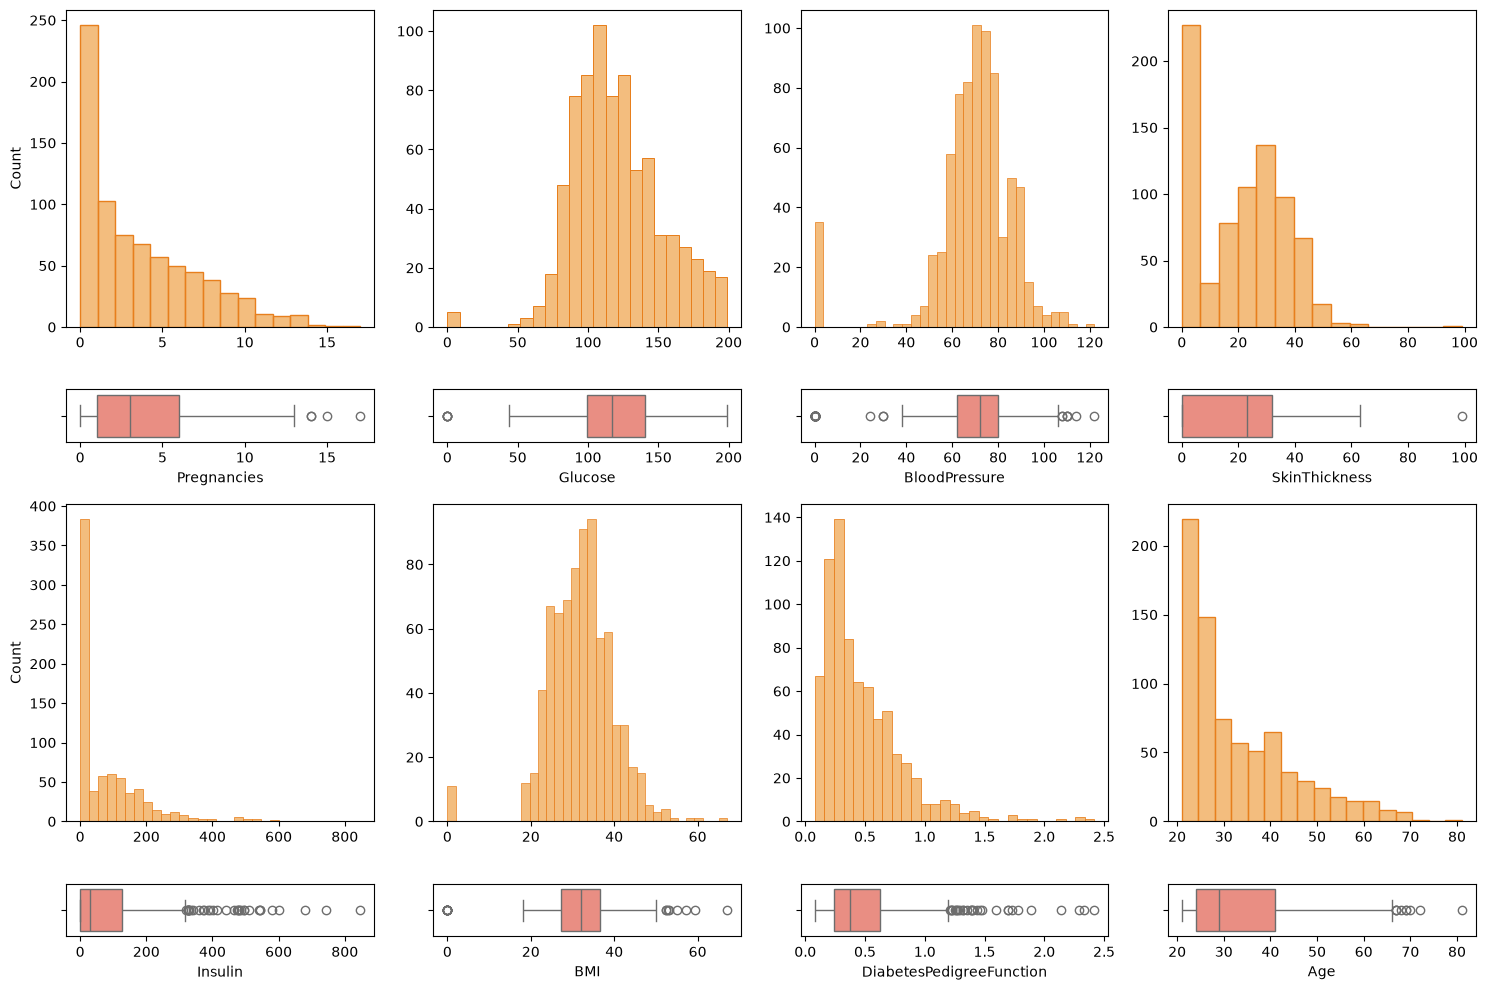

In [8]:
fig, axis = plt.subplots(4, 4, figsize = (15, 10), gridspec_kw={'height_ratios': [6, 1, 6, 1]})

sns.histplot(ax = axis[0, 0], data = df, x = "Pregnancies", color="#F0A753", edgecolor="#E77F1D").set(xlabel = None)
sns.boxplot(ax = axis[1, 0], data = df, x = "Pregnancies", color='salmon')
sns.histplot(ax = axis[0, 1], data = df, x = "Glucose", color="#F0A753", edgecolor="#E77F1D").set(xlabel = None, ylabel = None)
sns.boxplot(ax = axis[1, 1], data = df, x = "Glucose", color='salmon')
sns.histplot(ax = axis[0, 2], data = df, x = "BloodPressure", color="#F0A753", edgecolor="#E77F1D").set(xlabel = None, ylabel = None)
sns.boxplot(ax = axis[1, 2], data = df, x = "BloodPressure", color='salmon')
sns.histplot(ax = axis[0, 3], data = df, x = "SkinThickness", color="#F0A753", edgecolor="#E77F1D").set(xlabel = None, ylabel = None)
sns.boxplot(ax = axis[1, 3], data = df, x = "SkinThickness", color='salmon')
sns.histplot(ax = axis[2, 0], data = df, x = "Insulin", color="#F0A753", edgecolor="#E77F1D").set(xlabel = None)
sns.boxplot(ax = axis[3, 0], data = df, x = "Insulin", color='salmon')
sns.histplot(ax = axis[2, 1], data = df, x = "BMI", color="#F0A753", edgecolor="#E77F1D").set(xlabel = None, ylabel = None)
sns.boxplot(ax = axis[3, 1], data = df, x = "BMI", color='salmon')
sns.histplot(ax = axis[2, 2], data = df, x = "DiabetesPedigreeFunction", color="#F0A753", edgecolor="#E77F1D").set(xlabel = None, ylabel = None)
sns.boxplot(ax = axis[3, 2], data = df, x = "DiabetesPedigreeFunction", color='salmon')
sns.histplot(ax = axis[2, 3], data = df, x = "Age", color="#F0A753", edgecolor="#E77F1D").set(xlabel = None, ylabel = None)
sns.boxplot(ax = axis[3, 3], data = df, x = "Age", color='salmon')

plt.tight_layout()

plt.show()

A partir de los gráficos, se concluye que:

- **Pregnancies (Embarazos):** La mayoría de las observaciones se concentran en valores bajos. La distribución baja rápidamente y presenta algunos valores atípicos (*outliers*) mostrándonos que hay pacientes con sobre 15 embarazos.

* **Glucose (Glucosa):** Presenta una forma acampanada bastante simétrica centrada alrededor de los 110-120. Sin embargo, se observa un pequeño grupo anómalo en el valor 0. (Se debe poner ojo a los valores muy bajos y los valores en 0 ya que no es posible tener un valor de glucosa de 0 en la sangre de una persona viva)

* **BloodPressure (Presión Arterial):** Tiene una distribución simétrica con un pico central bien definido alrededor de los 70. Al igual que la glucosa, cuenta con algunos valores atípicos en cero (lo cual hay que definir que hacer con ellos, ya que es fisiológicamente que una persona viva tenga 0 de presión arterial) y otrosen valores sobre 100 (los cuales pueden ser reales y relevantes).

* **SkinThickness (Grosor de la Piel):** Si no fuera por la cantidad abrupta de ceros que hay, tendría una distribución simétrica con un pico central bien definido alrededor de los 30. Presenta un solo outlier que pareciera haber sido un error debido a que es clinicamente improbable esa medida.

* **Insulin (Insulina):** Tiene un sesgo positivo altísimo. Más de la mitad de los datos se acumulan en valores cercanos a cero, y también se observan hartos valores atípicos elevados que llegan hasta más de 800. (Se debe poner ojo a los valores muy bajos y los valores en 0 ya que no es fisiológicamente posible tener un valor real de insulina en sangre de 0)

* **BMI (Índice de Masa Corporal):** Su distribución es razonablemente simétrica con un promedio centrado, pero cuenta con valores atípicos hacia los valores altos (superiores a 50, incluso hasta 60) y algunos registros aislados en 0 (los valores en 0, nuevamente son fisiológicamente imposibles, sin embargo, los outliers altos, pueden ser reales y relevantes).

* **DiabetesPedigreeFunction (Función de Pedigrí de la Diabetes):** Muestra una distribución sesgada hacia la derecha, o sea, un sesgo positivo, donde la gran mayoría de los valores se concentran entre 0.2 y 0.5 aprox, con una cola larga y varios valores atípicos en numeros mayores (hasta 2.5). Estos outliers con valores más elevados de lo normal podrían ser valores reales y además muy relevantes.

* **Age (Edad):** La distribución también está sesgada a la derecha, indicandonos que la población del dataset es predominantemente joven (con un pico importante entre los 20 y 30 años), disminuyendo de forma gradual hacia edades más avanzadas (hasta los 80 años).

### 4to Paso EDA: Análisis de variables multivariante

**Análisis numérico-numérico**

In [9]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='str')

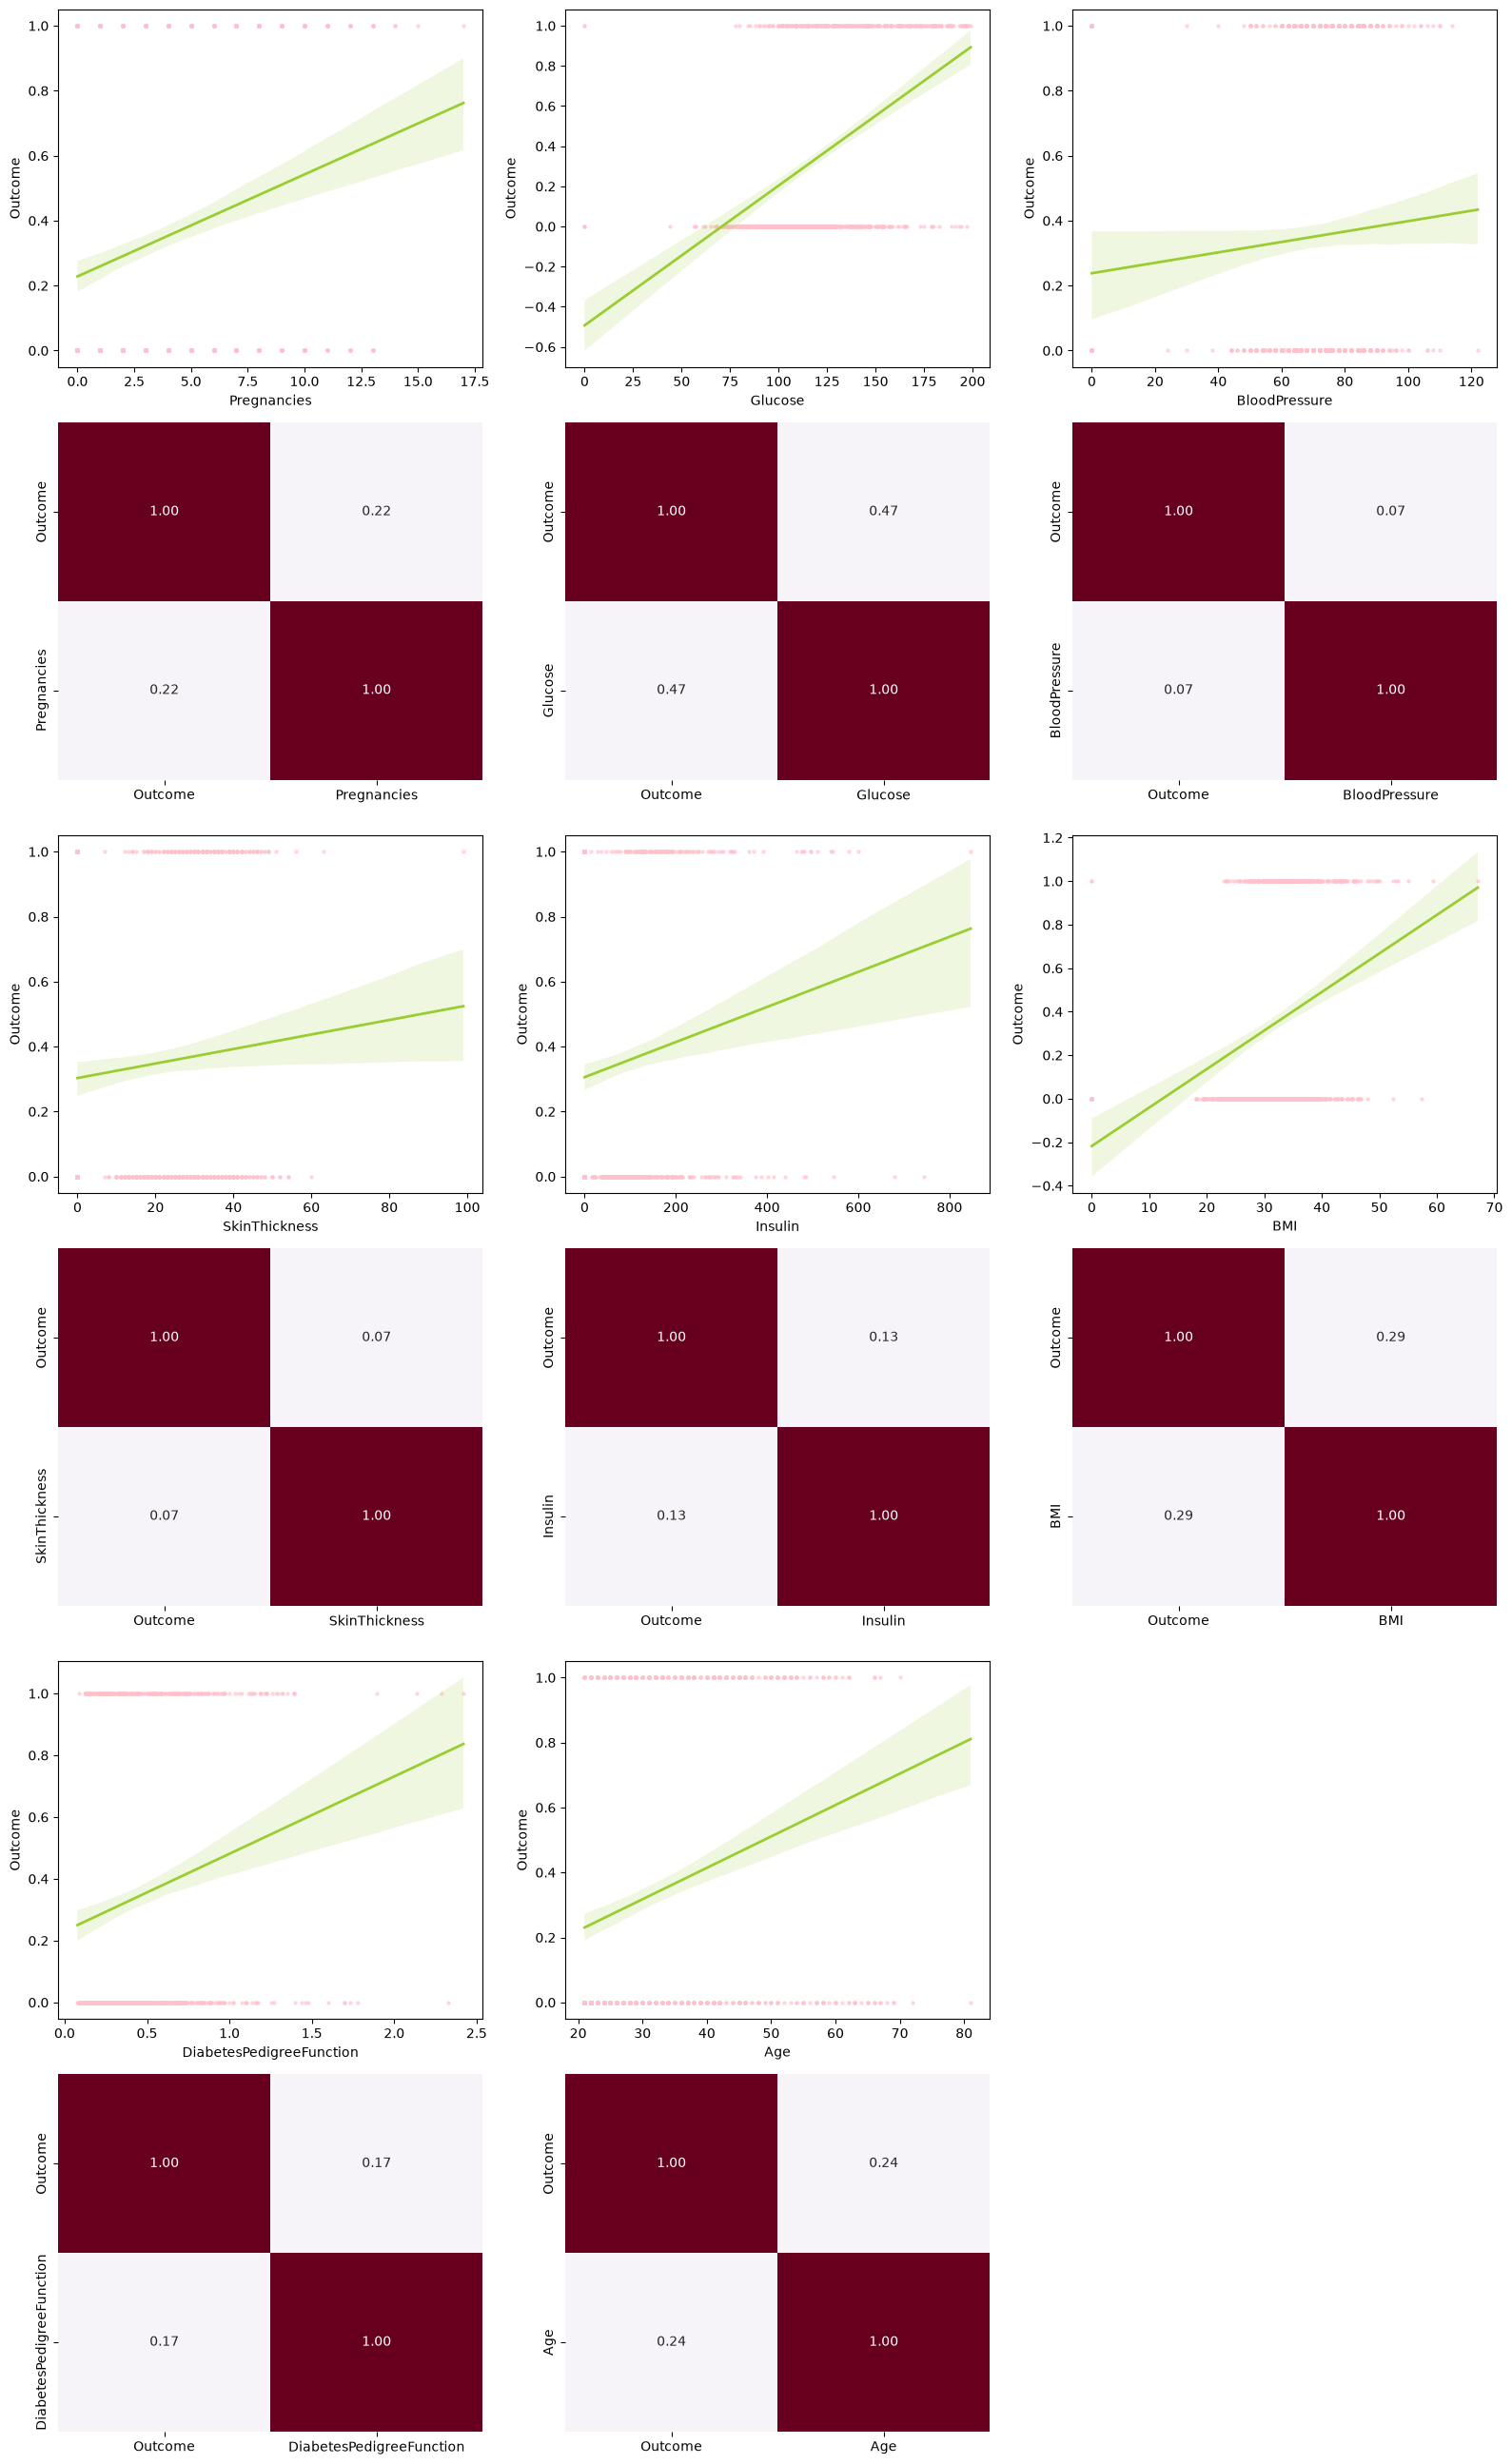

In [10]:
fig, axis = plt.subplots(6,3, figsize=(16,26))

sns.regplot(ax = axis[0,0], data = df, x = "Pregnancies", y = "Outcome", scatter_kws = {'s': 5 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["Outcome","Pregnancies"]].corr(), annot=True, fmt = '.2f', ax = axis[1,0], cmap='PuRd', cbar=False)

sns.regplot(ax = axis[0,1], data = df, x = "Glucose", y = "Outcome", scatter_kws = {'s': 5 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["Outcome","Glucose"]].corr(), annot=True, fmt = '.2f', ax = axis[1,1], cmap='PuRd', cbar=False)

sns.regplot(ax = axis[0,2], data = df, x = "BloodPressure", y = "Outcome", scatter_kws = {'s': 5 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["Outcome","BloodPressure"]].corr(), annot=True, fmt = '.2f', ax = axis[1,2], cmap='PuRd', cbar=False)

sns.regplot(ax = axis[2,0], data = df, x = "SkinThickness", y = "Outcome", scatter_kws = {'s': 5 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["Outcome","SkinThickness"]].corr(), annot=True, fmt = '.2f', ax = axis[3,0], cmap='PuRd', cbar=False)

sns.regplot(ax = axis[2,1], data = df, x = "Insulin", y = "Outcome", scatter_kws = {'s': 5 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["Outcome","Insulin"]].corr(), annot=True, fmt = '.2f', ax = axis[3,1], cmap='PuRd', cbar=False)

sns.regplot(ax = axis[2,2], data = df, x = "BMI", y = "Outcome", scatter_kws = {'s': 5 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["Outcome","BMI"]].corr(), annot=True, fmt = '.2f', ax = axis[3,2], cmap='PuRd', cbar=False)

sns.regplot(ax = axis[4,0], data = df, x = "DiabetesPedigreeFunction", y = "Outcome", scatter_kws = {'s': 5 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["Outcome","DiabetesPedigreeFunction"]].corr(), annot=True,fmt = '.2f', ax = axis[5,0], cmap='PuRd', cbar=False)

sns.regplot(ax = axis[4,1], data = df, x = "Age", y = "Outcome", scatter_kws = {'s': 5 ,'alpha':0.5, 'color':'pink'}, line_kws = {'color':'yellowgreen', 'linewidth': 2})
sns.heatmap(df[["Outcome","Age"]].corr(), annot=True,fmt = '.2f', ax = axis[5,1], cmap='PuRd', cbar=False)

fig.delaxes(axis[4,2])
fig.delaxes(axis[5,2])
            
plt.tight_layout()

plt.show()

Los diagramas de correlación permiten identificar la dirección y la intensidad de correlación entre las variables predictoras y la presencia de Diabetes (**'Outcome'**). Estas correlaciones sirven como análisis exploratorio previo al modelo, permitiendo detectar variables potencialmente relevantes.

Analicemos primero los gráficos que nos muestran una correlación **POSITIVA**.

* Glucosa (**Glucose**): Con una correlación de 0.47 es la variable **más influyente y predictiva**. Muestra la pendiente más pronunciada en la regresión indicandonos que a mayor nivel de glucosa, la probabilidad de tener diabetes aumenta considerablemente.

* **BMI**: Con una correlación de 0.29, presenta una relación directa importante y una pendiente fuerte. Un índice de masa corporal más alto aumenta significativamente la probabilidad de dar positivo en Diabetes.


* Edad (**Age**): Con una correlación de 0.24, existe una tendencia positiva moderada. La probabilidad de diagnóstico aumenta a medida que aumenta la edad del paciente.


* Embarazos (**Pregnancies)**: Con una correlación de 0.22, tiene una relación positiva moderada. A mayor número de embarazos, se observa una mayor probabilidad de presencia de Diabetes.

Analicemos ahora los gráficos que nos muestran una correlación **LEVE O MODERADA**.

* Función de Pedigrí de la Diabetes (**DiabetesPedigreeFunction)**: Con una correlación de 0.17, nos muestra una relación positiva leve. Un antecedente genético más alto se asocia moderadamente con el riesgo de diabetes.

* Insulina (**Insulin**): Con una correlación de 0.13 tenemos una relación positiva débil. Aunque la pendiente crece, la correlación lineal directa con Outcome es baja (posiblemente afectada por los valores en 0 o atípicos).

Sigamos con los gráficos con **NULA O CASI NULA** Relación Lineal

* Presión Arterial (**BloodPressurey SkinThickness**): Ambas con una correlación de 0.07, muestran una línea de tendencia casi plana y una correlación mínima con Outcome. De forma aislada e individual, no son buenas variables predictoras en un modelo lineal.


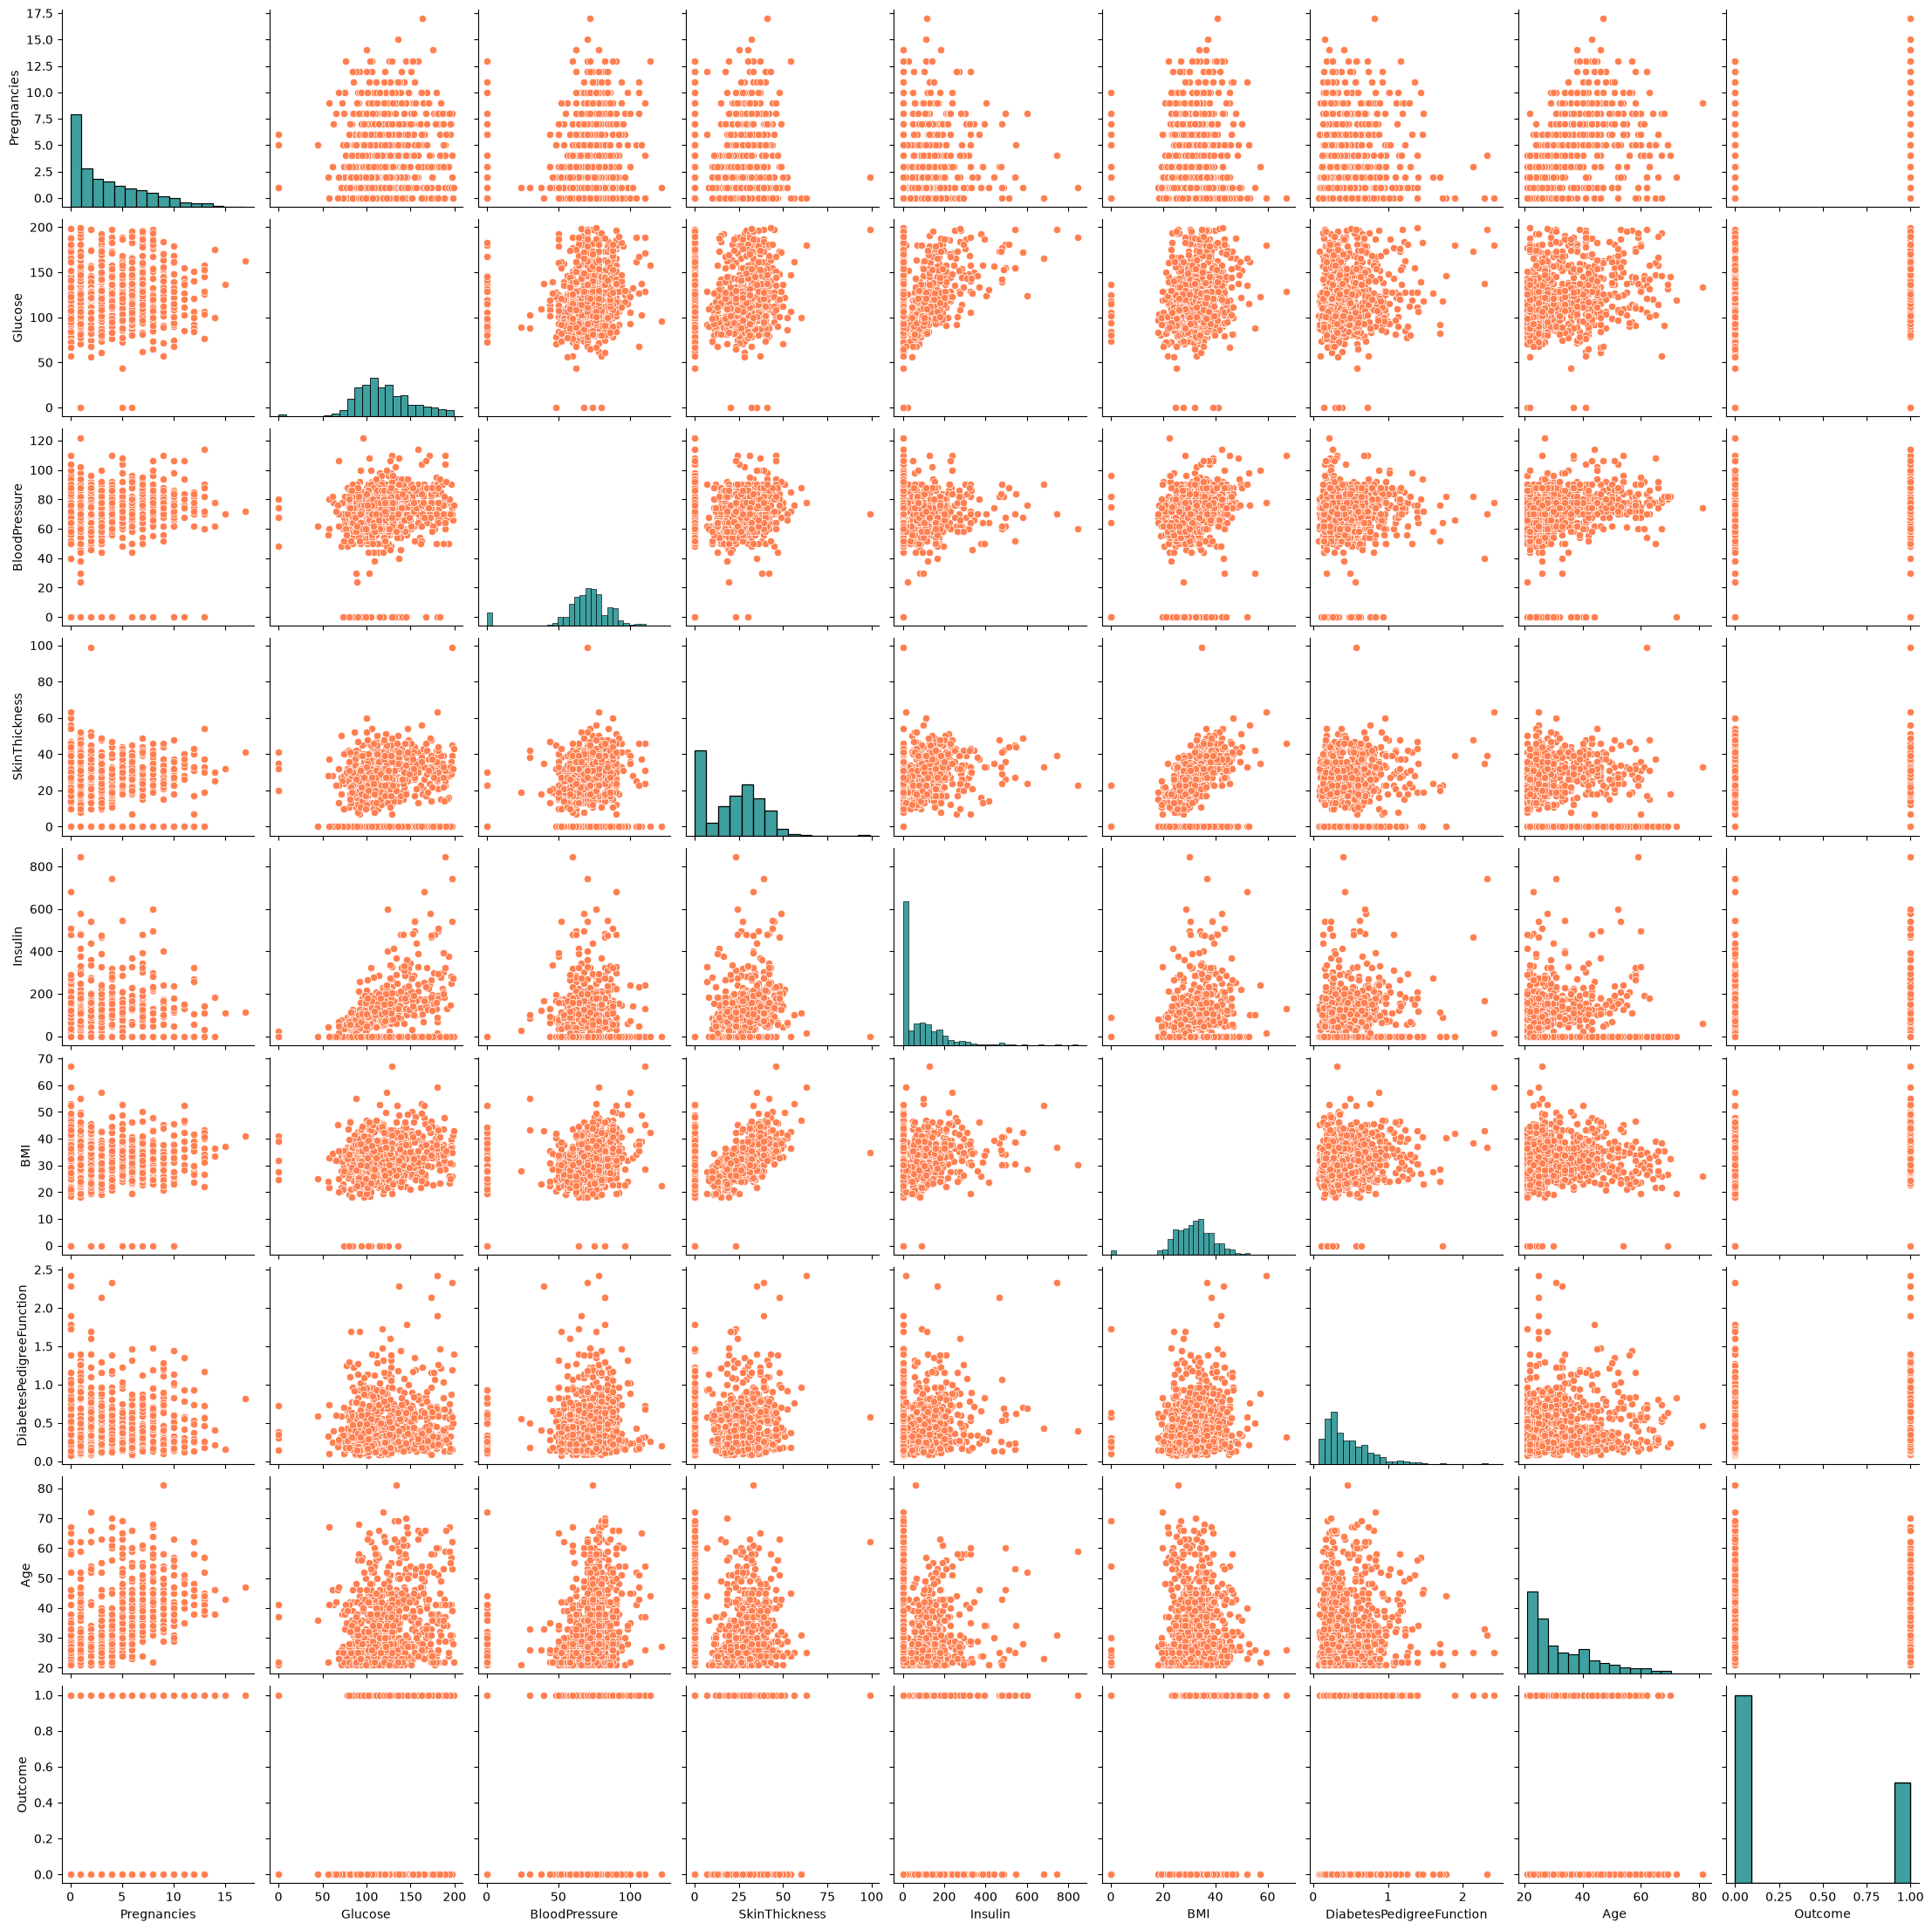

In [11]:
sns.pairplot(data = df, plot_kws={'color': 'coral'}, diag_kws={'color': 'teal'})

plt.show()

### 5to Paso EDA: Ingeniería de características

**Análisis de outliers**


In [12]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


Los outliers altos no los eliminaré ni imputaré, ya que, como mencioné anteriormente, son valores que clinicamente pueden ocurrir y pueden ser relevantes. Los valores que si imputaremos son los ceros en todas las columnas que hayan. Primero convertiré los ceros en valores nulos reales (NaN) y luego imputaré.

In [13]:
columnas_con_ceros = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
]

df[columnas_con_ceros] = df[columnas_con_ceros].replace(0, np.nan)


In [14]:
for col in columnas_con_ceros:
  mediana = df[col].median()  
  df[col] = df[col].fillna(mediana)

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


In [15]:
print("Valores nulos antes de imputar:")
print(df[columnas_con_ceros].isnull().sum())

print("\nCantidad de ceros restantes:")
print((df[columnas_con_ceros] == 0).sum())

print("\nValores nulos después de imputar:")
print(df[columnas_con_ceros].isnull().sum())


Valores nulos antes de imputar:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64

Cantidad de ceros restantes:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64

Valores nulos después de imputar:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


**Análisis de valores faltantes**


In [16]:
df.isnull().sum().sort_values(ascending=False)

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

No tenemos valores faltantes.

**Inferencia de nuevas características**

No realizaré fusiones de características ya que, por el tipo de variables e información que estas continen, no es un paso necesario en este caso concreto. 

**Escalado de Valores**

No es necesario que las variables predictoras estén normalizadas, ya que los árboles de decisión no se ven afectados por la escala de los datos debido a la forma en la que funcionan

**Separación Conjunto de Train y Test**

In [17]:
X = df.drop(columns=['Outcome'])
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

X_train.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
60,2,84.0,72.0,29.0,125.0,32.3,0.304,21
618,9,112.0,82.0,24.0,125.0,28.2,1.282,50
346,1,139.0,46.0,19.0,83.0,28.7,0.654,22
294,0,161.0,50.0,29.0,125.0,21.9,0.254,65
231,6,134.0,80.0,37.0,370.0,46.2,0.238,46


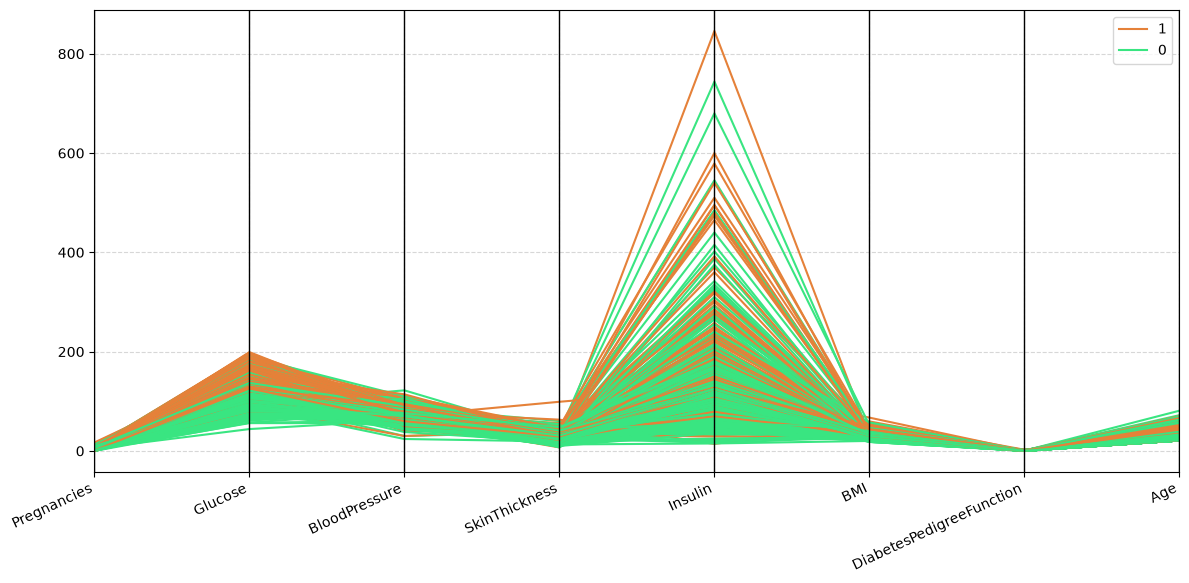

In [18]:
df = X
df["Outcome"] = y

plt.figure(figsize=(14, 6))
pd.plotting.parallel_coordinates(df, "Outcome", color = ("#E58139", "#39E581"))
plt.xticks(rotation=25, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Paso 3: Construye un modelo de árbol de decisión

In [19]:
model = DecisionTreeClassifier(random_state=42)

model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

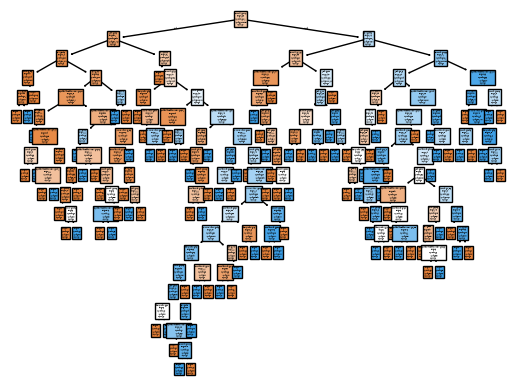

In [20]:
plot_tree(model, feature_names = list(X_train.columns), class_names = ['0', '1'], filled = True)

plt.show()

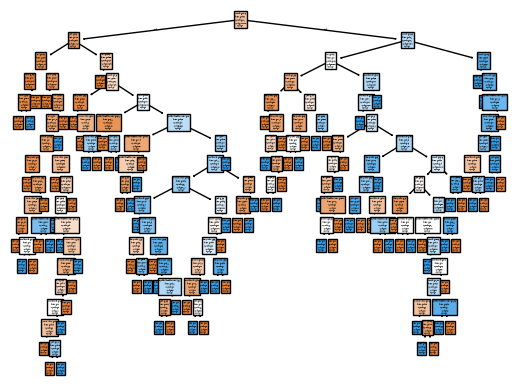

In [21]:
model_entropia = DecisionTreeClassifier(criterion='entropy',random_state=42)
model_log_loss = DecisionTreeClassifier(criterion='log_loss',random_state=42)

model_entropia.fit(X_train,y_train)
model_log_loss.fit(X_train,y_train)

plot_tree(model_entropia,feature_names = list(X_train.columns), class_names = ['0','1'],filled = True)

plt.show()

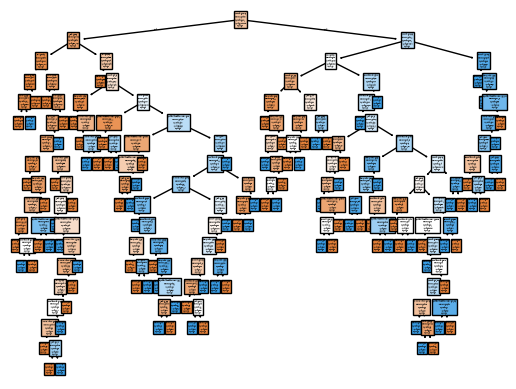

In [22]:
plot_tree(model_log_loss,feature_names = list(X_train.columns), class_names = ['0','1'],filled = True)
plt.show()


In [23]:
y_pred = model.predict(X_test)
y_pred_entropia = model_entropia.predict(X_test)
y_pred_log_loss = model_log_loss.predict(X_test)

In [24]:
print(f'Precisión Árbol de Decisión Gini:{accuracy_score(y_test,y_pred)}')
print(f'Precisión Árbol de Decisión Entropía:{accuracy_score(y_test,y_pred_entropia)}')
print(f'Precisión Árbol de Decisión Perdida Log:{accuracy_score(y_test,y_pred_log_loss)}')


Precisión Árbol de Decisión Gini:0.7207792207792207
Precisión Árbol de Decisión Entropía:0.7207792207792207
Precisión Árbol de Decisión Perdida Log:0.7207792207792207


## Paso 4: Optimiza el modelo anterior

In [25]:
param_grid = {
    # Criterio para medir la calidad de la división
    'criterion': ['gini', 'entropy', 'log_loss'],
    
    # Estrategia usada para elegir la división en cada nodo
    'splitter': ['best', 'random'],
    
    # Profundidad máxima del árbol (controla el sobreajuste)
    'max_depth': [None, 3, 5, 7, 10, 15, 20],
    
    # Número mínimo de muestras requeridas para dividir un nodo interno
    'min_samples_split': [2, 5, 10, 20],
    
    # Número mínimo de muestras requeridas en un nodo hoja
    'min_samples_leaf': [1, 2, 4, 8],
    
    # Número máximo de características a considerar al buscar la mejor división
    'max_features': [None, 'sqrt', 'log2']
}

In [26]:
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

In [27]:
grid_search.fit(X_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy', ...], 'max_depth': [None, 3, ...], 'max_features': [None, 'sqrt', ...], 'min_samples_leaf': [1, 2, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for call

In [30]:
print(f'Mejores Parámetros: {grid_search.best_params_}')
print(f'Mejor accuracy: {grid_search.best_score_}')

mejor_modelo = grid_search.best_estimator_

Mejores Parámetros: {'criterion': 'gini', 'max_depth': 5, 'max_features': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'splitter': 'random'}
Mejor accuracy: 0.758963081434093


## Paso 5: Guarda el modelo

In [31]:
dump(mejor_modelo, open("../models/decission_tree_grid_search_42.model", "wb"))